# Ant Colony Optimization for Network Routing

**Objective:** Select a preferred route from source A to destination D by exploring paths and updating pheromone levels. This delay-based simulation does not currently optimize battery life or perform real network routing.

## 1. Import libraries

In [1]:
import random
import matplotlib.pyplot as plt

random.seed(42)  # Optional: reproducible simulation

## 2. Define network topology

Each dictionary entry specifies a router's neighbours and link delay in milliseconds.

In [2]:
network = {
    'A': {'B': 30, 'C': 10},
    'B': {'D': 20},
    'C': {'D': 5},
    'D': {}
}

# A -> B -> D = 50 ms
# A -> C -> D = 15 ms

## 3. Initialize pheromones and parameters

In [3]:
pheromones = {
    ('A', 'B'): 1.0,
    ('B', 'D'): 1.0,
    ('A', 'C'): 1.0,
    ('C', 'D'): 1.0
}

alpha = 1.0
beta = 1.0
evaporation = 0.1
iterations = 20
ants_per_iteration = 5

## 4. Run the ACO simulation

Forward ants choose neighbours probabilistically using pheromone and delay heuristic scores. Their paths and delays are recorded. Pheromone then evaporates and successful ants deposit a reward proportional to inverse path delay.

In [4]:
for step in range(1, iterations + 1):
    ant_trips = []

    # Forward-ant exploration
    for _ in range(ants_per_iteration):
        current = 'A'
        path = ['A']
        total_delay = 0

        while current != 'D':
            neighbors = network[current]
            scores = {}

            for nxt, delay in neighbors.items():
                tau = pheromones[(current, nxt)] ** alpha
                eta = (1.0 / delay) ** beta
                scores[nxt] = tau * eta

            # Roulette-wheel selection
            total_score = sum(scores.values())
            pick = random.uniform(0, total_score)
            cumulative = 0
            chosen = None

            for nxt, score in scores.items():
                cumulative += score
                if pick <= cumulative:
                    chosen = nxt
                    break

            total_delay += neighbors[chosen]
            path.append(chosen)
            current = chosen

        ant_trips.append((path, total_delay))

    # Evaporate pheromone on every link
    for edge in pheromones:
        pheromones[edge] *= (1 - evaporation)

    # Deposit pheromone on each ant's successful route
    for path, delay in ant_trips:
        reward = 100.0 / delay
        for i in range(len(path) - 1):
            edge = (path[i], path[i + 1])
            pheromones[edge] += reward

## 5. Display final pheromone table

In [5]:
print("=== FINAL PHEROMONE ROUTING TABLE ===")
for edge, level in pheromones.items():
    print(f"Link {edge[0]} -> {edge[1]} : Pheromone = {level:.2f}")

=== FINAL PHEROMONE ROUTING TABLE ===
Link A -> B : Pheromone = 0.12
Link B -> D : Pheromone = 0.12
Link A -> C : Pheromone = 292.93
Link C -> D : Pheromone = 292.93


## 6. Select the preferred route and calculate delay

For this simple two-route topology, select the source's next hop with the highest pheromone and construct the route.

In [6]:
best_next_hop = max(
    network['A'],
    key=lambda nxt: pheromones[('A', nxt)]
)

optimal_path = ['A', best_next_hop, 'D']
optimal_delay = (
    network['A'][best_next_hop]
    + network[best_next_hop]['D']
)

print("\\n=== ROUTING DECISION ===")
print(f"Optimal Route Selected : {' -> '.join(optimal_path)}")
print(f"Total End-to-End Delay : {optimal_delay} ms")

\n=== ROUTING DECISION ===
Optimal Route Selected : A -> C -> D
Total End-to-End Delay : 15 ms


## 7. Plot pheromone levels

Orange bars represent links through B (the congested route); green bars represent links through C (the faster route).

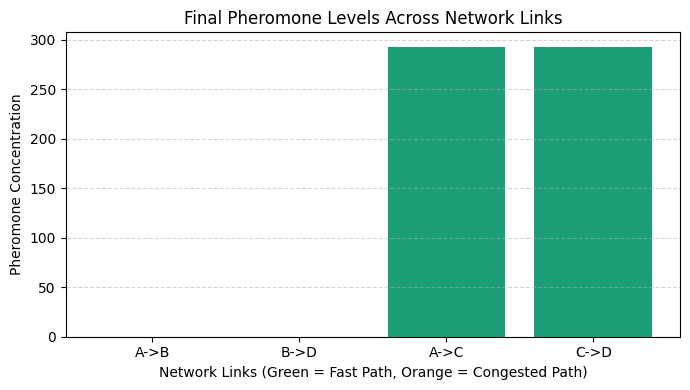

In [7]:
links = [f"{u}->{v}" for u, v in pheromones.keys()]
values = list(pheromones.values())
colors = ['#d95f02' if 'B' in link else '#1b9e77' for link in links]

plt.figure(figsize=(7, 4))
plt.bar(links, values, color=colors)
plt.title("Final Pheromone Levels Across Network Links")
plt.ylabel("Pheromone Concentration")
plt.xlabel("Network Links (Green = Fast Path, Orange = Congested Path)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Notes

- Initial pheromone on every link is `1.0`.
- Heuristic = `1 / link_delay`.
- Score = `pheromone**alpha * heuristic**beta`.
- Evaporation multiplies pheromone by `(1 - evaporation)`.
- Deposit reward = `100 / total_path_delay`.
- This version optimizes for delay only; battery status is not included.
- Backward-ant behavior is simplified: pheromone is deposited directly on the recorded forward path.